# BrushCue Example: Charcoal Sketch

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/charcoal_sketch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/charcoal-sketch

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


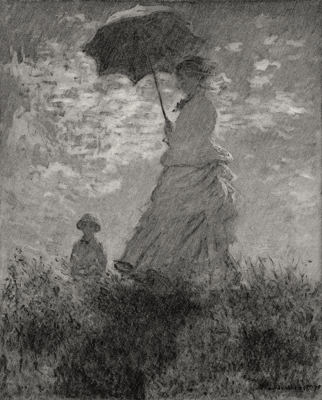

In [1]:
import io
from PIL import Image

import brushcue as bc

stroke_size = 14.0
darkness = 1.15
smudge = 0.6
paper_texture = 0.65
input_image = bc.Composition.monet_women_with_parasol()
bounds = input_image.bounds()
reference_scale = (
    bc.Float.max(1.0, bc.Float.min(bounds.width(), bounds.height())) / 1000.0
)
radius = bc.Float.max(0.5, (stroke_size * reference_scale))
graph = input_image.spacial_effect_shader(
    "let lo = image_bounds.xy + vec2f(0.5);\nlet hi = image_bounds.zw - vec2f(0.5);\nlet p = clamp(position, lo, hi);\nlet source = sample(p);\nif (source.a <= 0.0) { return vec4f(0.0); }\nlet uv = (p - image_bounds.xy) / reference_scale;\n// Alpha-weighted neighborhoods ignore colors hidden in transparent pixels.\nvar total = vec3f(0.0);\nvar weights = 0.0;\nfor (var y = -3; y <= 3; y = y + 1) {\n    for (var x = -3; x <= 3; x = x + 1) {\n        let offset = vec2f(f32(x), f32(y));\n        let c = sample(clamp(p + offset * radius / 3.0, lo, hi));\n        let spatial = exp(-dot(offset, offset) * 0.22);\n        let weight = spatial * c.a;\n        total += c.rgb * weight;\n        weights += weight;\n    }\n}\nlet local = total / max(weights, 0.0001);\nlet tooth = noise(uv * 0.8);\n// Elongated noise breaks pigment into broad, diagonal dry-media strokes.\nlet stroke_uv = vec2f(uv.x + uv.y * 0.45, uv.y - uv.x * 0.45);\nlet strokes = noise(stroke_uv / vec2f(2.5, 22.0));\nlet gray = luma(source.rgb);\nlet blurred = luma(local);\nlet tone = mix(gray, blurred, smudge * 0.9);\nlet contour = max(blurred - gray, 0.0) * (1.0 - smudge * 0.6);\nlet density = clamp((pow(1.0 - tone, 1.1) + contour * 1.4) * darkness, 0.0, 1.0);\nlet deposit = mix(1.0, clamp(0.55 + tooth * 0.7 + strokes * 0.25, 0.0, 1.25), paper_texture);\nlet ink = clamp(density * deposit, 0.0, 1.0);\nlet paper = vec3f(0.98, 0.965, 0.935) * (1.0 - paper_texture * 0.045 * tooth);\nlet result = mix(paper, vec3f(0.055, 0.05, 0.045), ink);\nreturn vec4f(clamp(result, vec3f(0.0), vec3f(1.0)), source.a);",
    "fn hash(p: vec2f) -> f32 {\n    let q = fract(p * vec2f(0.1031, 0.11369));\n    let n = dot(q, q.yx + vec2f(19.19));\n    return fract((q.x + q.y + n) * (q.x + n));\n}\nfn noise(p: vec2f) -> f32 {\n    let i = floor(p);\n    let f = fract(p);\n    let u = f * f * (vec2f(3.0) - 2.0 * f);\n    return mix(mix(hash(i), hash(i + vec2f(1.0, 0.0)), u.x),\n        mix(hash(i + vec2f(0.0, 1.0)), hash(i + vec2f(1.0)), u.x), u.y);\n}\nfn luma(c: vec3f) -> f32 {\n    return dot(clamp(c, vec3f(0.0), vec3f(1.0)), vec3f(0.299, 0.587, 0.114));\n}",
    0.0,
    bc.Dictionary.create()
    .add("image_bounds", bounds)
    .add("reference_scale", reference_scale)
    .add("radius", radius)
    .add("darkness", darkness)
    .add("smudge", smudge)
    .add("paper_texture", paper_texture),
    bc.ColorRepresentation.srgb(),
).crop(bounds)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
